In [2]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas as pd
from IPython.display import Latex

In [30]:
#Setup A


x_dat = np.array([0.780,
1.270,
1.760,
1.960,
2.250,
2.450])

y_dat = np.array([0.270,
0.480,
0.660,
0.750,
0.840,
0.90])

y_err = np.array([0.01,
0.01,
0.03,
0.01,
0.01,
0.02])

In [28]:
#Setup B
"""
x_dat = np.array([0.29,
0.39,
0.490,
0.54,
0.69,
0.78])



y_dat = np.array([0.24,
0.3,
0.45,
0.46,
0.57,
0.79])

y_err = np.array([0.01,
0.03,
0.01,
0.01,
0.01,
0.01])
"""

In [20]:
# Setup C
"""
x_dat = np.array([1.27,
2.25,
3.23,
3.72,
4.21,
4.41])

y_dat = np.array([0.21,
0.49,
0.58,
0.61,
0.80,
0.85])

y_err = np.array([0.01,
0.03,
0.04,
0.02,
0.03,
0.02])
"""

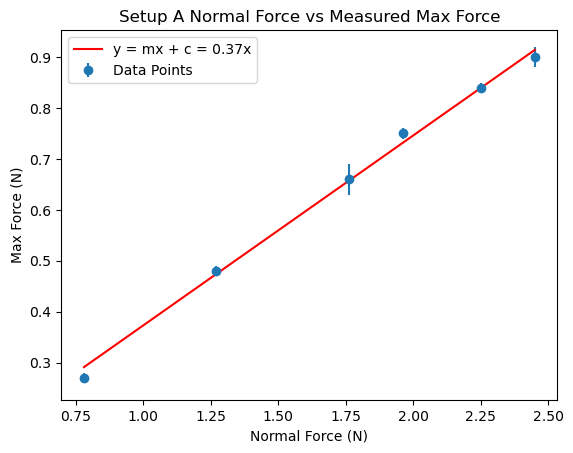

In [7]:
# Model without Constant

dict = {"Independent": x_dat, "Dependent": y_dat}
df = pd.DataFrame(dict)
model = sm.OLS(df["Dependent"], x_dat).fit()

x = np.linspace(x_dat.min(), x_dat.max(), 100)
#x = np.linspace(0, x_dat.max(), 100)
predictions = model.predict(x)

plt.errorbar(x_dat, y_dat, yerr=y_err, fmt='o', label='Data Points')
plt.plot(x, predictions, c='r', label=f'y = mx + c = {model.params.iloc[0]:.2f}x')
plt.title('Setup A Normal Force vs Measured Max Force')
plt.xlabel('Normal Force (N)')
plt.ylabel('Max Force (N)')
plt.legend()
#plt.savefig('Errorbar_plot.png')


0.011096137042433474


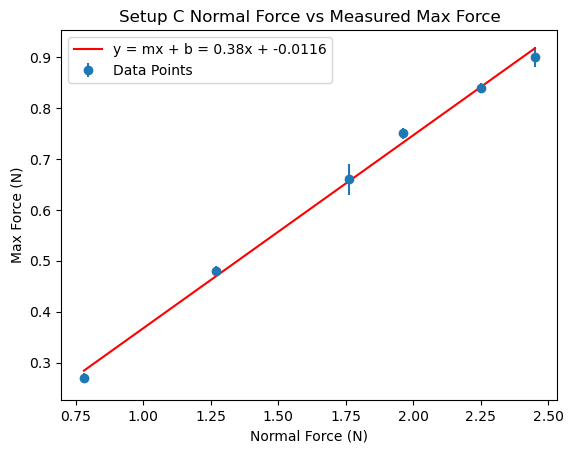

In [31]:
# Model with Constant

dict = {"Independent": x_dat, "Dependent": y_dat}
df = pd.DataFrame(dict)
x_constant = sm.add_constant(df["Independent"])
model_c = sm.OLS(df["Dependent"], x_constant).fit()

x = np.linspace(x_dat.min(), x_dat.max(), 100)
#x = np.linspace(0, x_dat.max(), 100)
x_predictions = sm.add_constant(x)
predictions = model_c.predict(x_predictions)

plt.errorbar(x_dat, y_dat, yerr=y_err, fmt='o', label='Data Points')
plt.plot(x, predictions, c='r', label=f'y = mx + b = {model_c.params.iloc[1]:.2f}x + {model_c.params.iloc[0]:.4f}')
plt.title('Setup C Normal Force vs Measured Max Force')
plt.xlabel('Normal Force (N)')
plt.ylabel('Max Force (N)')
plt.legend()
print(model_c.bse.iloc[1])
#plt.savefig('Errorbar_plot.png')

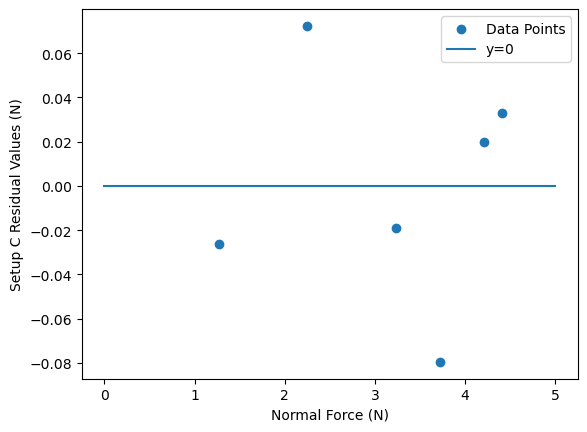

In [26]:
# Residual Plot for above
X2 = np.linspace(0, 5, 100)
Y2 = np.linspace(0, 0, 100)

plt.scatter(x_dat, y_dat - model_c.predict(sm.add_constant(x_dat)), label='Data Points')
plt.plot(X2, Y2, label='y=0')
plt.ylabel('Setup C Residual Values (N)')
plt.xlabel('Normal Force (N)')
plt.legend()
plt.show()